In [182]:
import pandas as pd
import numpy as np
from google.colab import files

up = files.upload()
name = list(up.keys())[0]
df = pd.read_csv(name)

print(df.shape)
df.info()
df.head(31)

Saving Data - mini project.csv to Data - mini project (20).csv
(30, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Name                        30 non-null     object 
 1   Age                         30 non-null     int64  
 2   Position                    30 non-null     object 
 3   League                      30 non-null     object 
 4   Goals                       30 non-null     object 
 5   Assists                     30 non-null     object 
 6   Clean Sheets                30 non-null     object 
 7   Avr_Rating                  30 non-null     float64
 8   Contract_Years              30 non-null     int64  
 9   Market_Value (milian euro)  30 non-null     int64  
dtypes: float64(1), int64(3), object(6)
memory usage: 2.5+ KB


,Name,Age,Position,League,Goals,Assists,Clean Sheets,Avr_Rating,Contract_Years,Market_Value (milian euro)
0,Lamine Yamal,19,FW,Spain,10,10,-,8.58,5,220
1,Raphinha,29,MF,Spain,12,3,-,8.56,4,70
2,Erling Haaland,26,FW,England,12,0,-,7.93,8,220
3,Kylian Mbappe,27,FW,Spainish,12,3,-,7.98,4,200
4,Michael Olise,24,FW,Germany,9,5,-,8.23,5,180
5,Jude Bellingham,23,MF,Spain,3,4,-,7.63,4,220
6,Pedri,23,MF,Spain,1,2,-,7.19,4,160
7,Joao Neves,22,MF,France,0,1,-,6.90,4,150
8,Kvicha Kvaratskhelia,25,FW,France,2,1,-,6.77,4,140
9,Vitinha,26,MF,France,3,1,-,7.67,4,140


In [183]:
df = df.rename(columns={'Market_Value (milian euro)': 'Value_M',
                        'Clean Sheets': 'Clean_Sheets'})

for c in ['Goals', 'Assists', 'Clean_Sheets']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

print(df[['Goals', 'Assists', 'Clean_Sheets']].isna().sum())

df[['Goals', 'Assists', 'Clean_Sheets']] = df[['Goals', 'Assists', 'Clean_Sheets']].fillna(0)

df.info()

Goals            1
Assists          1
Clean_Sheets    29
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Name            30 non-null     object 
 1   Age             30 non-null     int64  
 2   Position        30 non-null     object 
 3   League          30 non-null     object 
 4   Goals           30 non-null     float64
 5   Assists         30 non-null     float64
 6   Clean_Sheets    30 non-null     float64
 7   Avr_Rating      30 non-null     float64
 8   Contract_Years  30 non-null     int64  
 9   Value_M         30 non-null     int64  
dtypes: float64(4), int64(3), object(3)
memory usage: 2.5+ KB


In [184]:
# 1. Kiểm tra số lượng dòng trùng lặp
duplicates = df.duplicated().sum()
print(f"Số lượng dòng bị trùng lặp: {duplicates}")

# 2. Kiểm tra các giá trị độc nhất trong các cột phân loại (Categorical)
print("\nCác vị trí (Position) trong dữ liệu:")
print(df['Position'].unique())

print("\nCác giải đấu (League) trong dữ liệu:")
print(df['League'].unique())

# 3. Mô tả nhanh các cột số để xem có gì bất thường (lớn/nhỏ bất thường)
display(df.describe())

Số lượng dòng bị trùng lặp: 0

Các vị trí (Position) trong dữ liệu:
['FW' 'MF' 'FM' 'DF' 'DM' 'GK']

Các giải đấu (League) trong dữ liệu:
['Spain' 'England' 'Spainish' 'Germany' 'France' 'English']


,Age,Goals,Assists,Clean_Sheets,Avr_Rating,Contract_Years,Value_M
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,22.066667,3.500000,2.533333,0.133333,7.468667,5.066667,118.000000
std,9.874849,3.803356,2.129163,0.730297,0.471467,1.529781,57.992271
min,-28.000000,0.000000,0.000000,0.000000,6.770000,4.000000,-45.000000
25%,21.250000,1.000000,1.000000,0.000000,7.167500,4.000000,100.000000
50%,24.000000,2.500000,2.000000,0.000000,7.405000,4.500000,120.000000
75%,25.750000,4.000000,4.000000,0.000000,7.685000,5.000000,140.000000
max,30.000000,12.000000,10.000000,4.000000,8.580000,9.000000,220.000000


In [185]:
#1. Sửa lỗi chính tả
position_map = {'FM': 'FW', 'DM': 'DF'}
df['Position'] = df['Position'].replace(position_map)

league_map = {'English': 'England', 'Spainish': 'Spain'}
df['League'] = df['League'].replace(league_map)

#2. Sửa lỗi logic (xử lý số âm)
df['Age'] = df['Age'].abs()
df['Value_M'] = df['Value_M'].abs()

#3. Kiểm tra lại sau khi xử lý
print("\nKiểm tra lại Position sau khi map:", df['Position'].unique())
print("\nKiểm tra lại League sau khi map:", df['League'].unique())
print("Khoảng giá trị Age:", df['Age'].min(), "->", df['Age'].max())

# 4. Mô tả nhanh các cột số để xem có gì bất thường (lớn/nhỏ bất thường)
display(df.describe())


Kiểm tra lại Position sau khi map: ['FW' 'MF' 'DF' 'GK']

Kiểm tra lại League sau khi map: ['Spain' 'England' 'Germany' 'France']
Khoảng giá trị Age: 19 -> 30


,Age,Goals,Assists,Clean_Sheets,Avr_Rating,Contract_Years,Value_M
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,23.933333,3.500000,2.533333,0.133333,7.468667,5.066667,121.000000
std,2.947042,3.803356,2.129163,0.730297,0.471467,1.529781,51.199407
min,19.000000,0.000000,0.000000,0.000000,6.770000,4.000000,40.000000
25%,22.250000,1.000000,1.000000,0.000000,7.167500,4.000000,100.000000
50%,24.000000,2.500000,2.000000,0.000000,7.405000,4.500000,120.000000
75%,26.000000,4.000000,4.000000,0.000000,7.685000,5.000000,140.000000
max,30.000000,12.000000,10.000000,4.000000,8.580000,9.000000,220.000000


In [186]:
# Cập nhật thông tin giải đấu
league_map = {'England': 'Premier League', 'Spain': 'La Liga', 'France': 'Ligue 1', 'Germany': 'Bundesliga'}
df['League'] = df['League'].replace(league_map)

print("\nCác giải đấu (League) trong dữ liệu:")
print(df['League'].unique())


Các giải đấu (League) trong dữ liệu:
['La Liga' 'Premier League' 'Bundesliga' 'Ligue 1']


In [187]:
# 1. Tạo cột tổng đóng góp bàn thắng (G_A)
df['G_A'] = df['Goals'] + df['Assists']

# 2. Xem lại bảng sau khi thêm cột mới
print("Bảng sau khi tạo cột G_A:")
display(df[['Name', 'Position', 'League', 'Goals', 'Assists', 'G_A', 'Avr_Rating', 'Contract_Years', 'Value_M']].head(31))

Bảng sau khi tạo cột G_A:


,Name,Position,League,Goals,Assists,G_A,Avr_Rating,Contract_Years,Value_M
0,Lamine Yamal,FW,La Liga,10.0,10.0,20.0,8.58,5,220
1,Raphinha,MF,La Liga,12.0,3.0,15.0,8.56,4,70
2,Erling Haaland,FW,Premier League,12.0,0.0,12.0,7.93,8,220
3,Kylian Mbappe,FW,La Liga,12.0,3.0,15.0,7.98,4,200
4,Michael Olise,FW,Bundesliga,9.0,5.0,14.0,8.23,5,180
5,Jude Bellingham,MF,La Liga,3.0,4.0,7.0,7.63,4,220
6,Pedri,MF,La Liga,1.0,2.0,3.0,7.19,4,160
7,Joao Neves,MF,Ligue 1,0.0,1.0,1.0,6.90,4,150
8,Kvicha Kvaratskhelia,FW,Ligue 1,2.0,1.0,3.0,6.77,4,140
9,Vitinha,MF,Ligue 1,3.0,1.0,4.0,7.67,4,140


In [188]:
# Thực hiện mã hóa cho 2 cột chữ: Position và League

# drop_first=True giúp loại bỏ 1 cột cơ sở để tránh bẫy đa cộng tuyến
df_encoded = pd.get_dummies(df, columns=['Position', 'League'], drop_first=True, dtype=int)

# In ra danh sách các cột mới sau khi mã hóa
print("Số lượng cột ban đầu:", df.shape[1])
print("Số lượng cột sau khi mã hóa:", df_encoded.shape[1])
print("\nDanh sách toàn bộ các cột hiện tại:")
print(df_encoded.columns.tolist())

# Hiển thị bảng của các cột mới được sinh ra để kiểm tra
encoded_cols = [c for c in df_encoded.columns if 'Position_' in c or 'League_' in c]
display(df_encoded[['Name'] + encoded_cols].head(31))

Số lượng cột ban đầu: 11
Số lượng cột sau khi mã hóa: 15

Danh sách toàn bộ các cột hiện tại:
['Name', 'Age', 'Goals', 'Assists', 'Clean_Sheets', 'Avr_Rating', 'Contract_Years', 'Value_M', 'G_A', 'Position_FW', 'Position_GK', 'Position_MF', 'League_La Liga', 'League_Ligue 1', 'League_Premier League']


,Name,Position_FW,Position_GK,Position_MF,League_La Liga,League_Ligue 1,League_Premier League
0,Lamine Yamal,1,0,0,1,0,0
1,Raphinha,0,0,1,1,0,0
2,Erling Haaland,1,0,0,0,0,1
3,Kylian Mbappe,1,0,0,1,0,0
4,Michael Olise,1,0,0,0,0,0
5,Jude Bellingham,0,0,1,1,0,0
6,Pedri,0,0,1,1,0,0
7,Joao Neves,0,0,1,0,1,0
8,Kvicha Kvaratskhelia,1,0,0,0,1,0
9,Vitinha,0,0,1,0,1,0


In [189]:
# Cột mục tiêu cần dự đoán
y = df_encoded['Value_M']

# Các cột đặc trưng dùng để huấn luyện (bỏ Name và cột nhãn Value_M)
cols_to_drop = ['Name', 'Value_M']
if 'Club' in df_encoded.columns:
    cols_to_drop.append('Club')

X = df_encoded.drop(columns=cols_to_drop)

print(f"Ma trận X có kích thước: {X.shape[0]} dòng, {X.shape[1]} cột đặc trưng")
display(X.head(31))

Ma trận X có kích thước: 30 dòng, 13 cột đặc trưng


,Age,Goals,Assists,Clean_Sheets,Avr_Rating,Contract_Years,G_A,Position_FW,Position_GK,Position_MF,League_La Liga,League_Ligue 1,League_Premier League
0,19,10.0,10.0,0.0,8.58,5,20.0,1,0,0,1,0,0
1,29,12.0,3.0,0.0,8.56,4,15.0,0,0,1,1,0,0
2,26,12.0,0.0,0.0,7.93,8,12.0,1,0,0,0,0,1
3,27,12.0,3.0,0.0,7.98,4,15.0,1,0,0,1,0,0
4,24,9.0,5.0,0.0,8.23,5,14.0,1,0,0,0,0,0
5,23,3.0,4.0,0.0,7.63,4,7.0,0,0,1,1,0,0
6,23,1.0,2.0,0.0,7.19,4,3.0,0,0,1,1,0,0
7,22,0.0,1.0,0.0,6.90,4,1.0,0,0,1,0,1,0
8,25,2.0,1.0,0.0,6.77,4,3.0,1,0,0,0,1,0
9,26,3.0,1.0,0.0,7.67,4,4.0,0,0,1,0,1,0


In [190]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Chia 80% để học (Train) và 20% để kiểm tra (Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Khởi tạo bộ chuẩn hóa Z-score (StandardScaler)
scaler = StandardScaler()

# 3. Fit trên Train, Transform trên cả Train và Test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Kích thước X_train sau khi chuẩn hóa:", X_train_scaled.shape)
print("Kích thước X_test sau khi chuẩn hóa:", X_test_scaled.shape)
print("Đã hoàn thành toàn bộ bước Preprocessing!")

Kích thước X_train sau khi chuẩn hóa: (24, 13)
Kích thước X_test sau khi chuẩn hóa: (6, 13)
Đã hoàn thành toàn bộ bước Preprocessing!


In [191]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Khởi tạo 3 mô hình
models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=100, learning_rate=0.08, max_depth=3, random_state=42)
}

# 2. Huấn luyện và chấm điểm từng mô hình trên tập Test
summary = []

for name, model in models.items():
    # Học trên tập Train
    model.fit(X_train_scaled, y_train)

    # Dự đoán trên tập Test
    y_pred = model.predict(X_test_scaled)

    # Tính các chỉ số đo lường
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    summary.append({
        "Mô hình": name,
        "MAE (Triệu €)": round(mae, 2),
        "RMSE (Triệu €)": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })

# 3. Hiển thị bảng so sánh
df_results = pd.DataFrame(summary)
display(df_results)

,Mô hình,MAE (Triệu €),RMSE (Triệu €),R2 Score
0,Ridge Regression,21.03,22.05,0.5312
1,Random Forest,26.10,32.59,-0.0244
2,XGBoost,25.99,32.18,0.0014


In [192]:
# ==========================================
# 1. CHỌN MÔ HÌNH TỐT NHẤT ĐỂ ĐỐI CHIẾU THỰC TẾ
# ==========================================
# Chọn Random Forest (hoặc XGBoost tùy bảng kết quả của bạn cái nào R2 cao hơn)
best_model = models["Random Forest"]
y_pred_best = best_model.predict(X_test_scaled)

# Lấy lại tên cầu thủ trong tập Test để nhìn cho rõ
test_indices = X_test.index
comparison = pd.DataFrame({
    'Cầu thủ': df.loc[test_indices, 'Name'].values,
    'Vị trí': df.loc[test_indices, 'Position'].values,
    'Giá thực tế (M€)': y_test.values,
    'Dự đoán (M€)': np.round(y_pred_best, 1),
    'Chênh lệch (M€)': np.round(np.abs(y_test.values - y_pred_best), 1)
}).sort_values(by='Giá thực tế (M€)', ascending=False)

print("=== SO SÁNH GIÁ THỰC TẾ VS MÁY ĐOÁN TRÊN TẬP TEST ===")
display(comparison)

# ==========================================
# 2. XEM YẾU TỐ NÀO QUYẾT ĐỊNH GIÁ TRỊ NHẤT (FEATURE IMPORTANCE)
# ==========================================
importances = best_model.feature_importances_
feature_names = X.columns

df_importance = pd.DataFrame({
    'Đặc trưng': feature_names,
    'Độ quan trọng (%)': np.round(importances * 100, 2)
}).sort_values(by='Độ quan trọng (%)', ascending=False)

print("\n=== CÁC YẾU TỐ ẢNH HƯỞNG LỚN NHẤT ĐẾN GIÁ CẦU THỦ ===")
display(df_importance)

=== SO SÁNH GIÁ THỰC TẾ VS MÁY ĐOÁN TRÊN TẬP TEST ===


,Cầu thủ,Vị trí,Giá thực tế (M€),Dự đoán (M€),Chênh lệch (M€)
4,Kvicha Kvaratskhelia,FW,140,117.9,22.1
5,Vitinha,MF,140,139.4,0.6
1,Enzo Fernandez,MF,120,109.3,10.7
3,Rayan Cherki,MF,110,145.3,35.3
2,Arda Guler,MF,100,162.1,62.1
0,Joan Garcia,GK,45,70.8,25.8



=== CÁC YẾU TỐ ẢNH HƯỞNG LỚN NHẤT ĐẾN GIÁ CẦU THỦ ===


,Đặc trưng,Độ quan trọng (%)
4,Avr_Rating,22.97
6,G_A,21.74
0,Age,17.11
7,Position_FW,10.14
2,Assists,8.95
1,Goals,8.72
10,League_La Liga,3.80
5,Contract_Years,3.36
9,Position_MF,1.81
12,League_Premier League,0.88


/tmp/ipykernel_775/3780854024.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=top_features, x='Độ quan trọng (%)', y='Đặc trưng', palette='Blues_r')


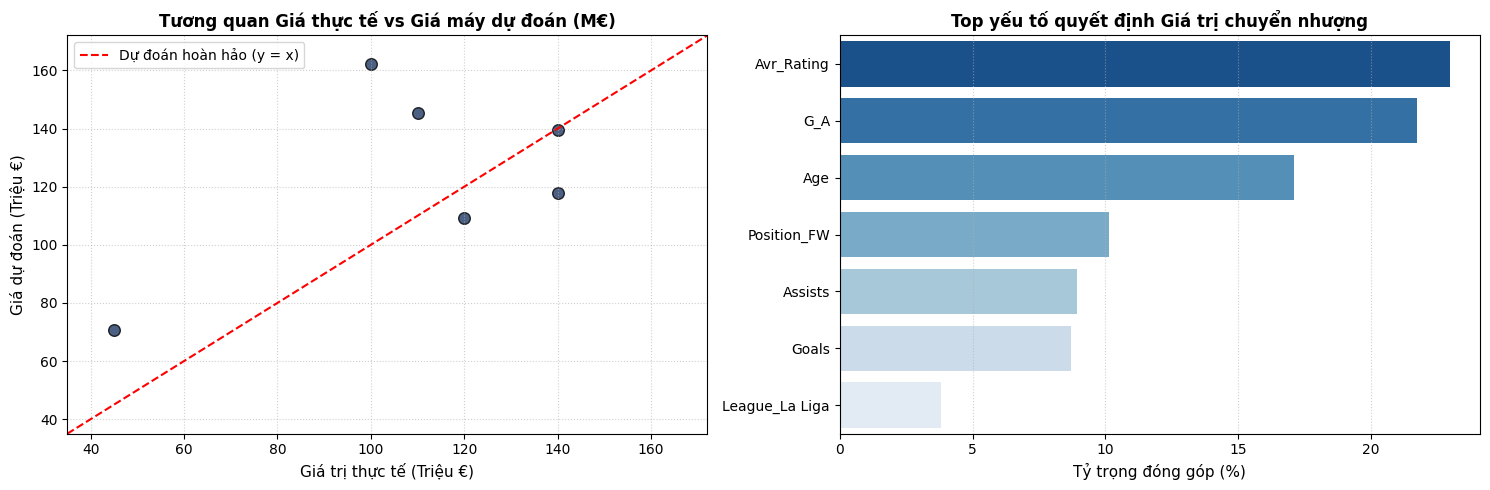

In [193]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# -------------------------------------------------------------
# Biểu đồ 1: Thực tế vs Dự đoán (Kiểm tra độ chệch của mô hình)
# -------------------------------------------------------------
axes[0].scatter(y_test, y_pred_best, color='#1F3864', alpha=0.8, edgecolors='k', s=70)
# Vẽ đường chéo lý tưởng 45 độ (y = x)
min_val = min(y_test.min(), y_pred_best.min()) - 10
max_val = max(y_test.max(), y_pred_best.max()) + 10
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5, label='Dự đoán hoàn hảo (y = x)')

axes[0].set_title('Tương quan Giá thực tế vs Giá máy dự đoán (M€)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Giá trị thực tế (Triệu €)', fontsize=11)
axes[0].set_ylabel('Giá dự đoán (Triệu €)', fontsize=11)
axes[0].set_xlim(min_val, max_val)
axes[0].set_ylim(min_val, max_val)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# -------------------------------------------------------------
# Biểu đồ 2: Top các đặc trưng quan trọng nhất (Feature Importance)
# -------------------------------------------------------------
top_features = df_importance.head(7)
sns.barplot(ax=axes[1], data=top_features, x='Độ quan trọng (%)', y='Đặc trưng', palette='Blues_r')
axes[1].set_title('Top yếu tố quyết định Giá trị chuyển nhượng', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tỷ trọng đóng góp (%)', fontsize=11)
axes[1].set_ylabel('')
axes[1].grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [194]:
# ==========================================
# CHƯƠNG TRÌNH TỰ NHẬP BẰNG BÀN PHÍM VÀ DỰ ĐOÁN
# ==========================================

print("=== NHẬP THÔNG TIN CẦU THỦ CẦN ĐỊNH GIÁ ===")
ten = input("1. Nhập tên cầu thủ: ")
tuoi = float(input("2. Nhập tuổi: "))
vi_tri = input("3. Nhập vị trí (FW / MF / DF / GK): ").strip().upper()
giai_dau = input("4. Nhập giải đấu (La Liga / Premier League / Bundesliga / Ligue 1): ").strip()
ban_thang = float(input("5. Nhập số bàn thắng: "))
kien_tao = float(input("6. Nhập số kiến tạo: "))
clean_sheets = float(input("7. Nhập số trận sạch lưới (Thủ môn thì nhập số, cầu thủ khác nhập 0): "))
rating = float(input("8. Nhập điểm Sofascore (ví dụ: 7.45): "))
hop_dong = float(input("9. Nhập số năm hợp đồng còn lại (ví dụ: 3): "))

# 1. Tính đặc trưng G_A
g_a = ban_thang + kien_tao

# 2. Tạo DataFrame đúng với các cột mà mô hình đã học
player_dict = {col: [0] for col in X.columns}

player_dict['Age'] = [tuoi]
player_dict['Goals'] = [ban_thang]
player_dict['Assists'] = [kien_tao]
player_dict['Clean_Sheets'] = [clean_sheets]
player_dict['Avr_Rating'] = [rating]
player_dict['Contract_Years'] = [hop_dong]
player_dict['G_A'] = [g_a]

# Đánh dấu cột vị trí (One-Hot)
pos_col = f"Position_{vi_tri}"
if pos_col in player_dict:
    player_dict[pos_col] = [1]

# Đánh dấu cột giải đấu (One-Hot)
league_col = f"League_{giai_dau}"
if league_col in player_dict:
    player_dict[league_col] = [1]

df_custom = pd.DataFrame(player_dict)[X.columns]

# 3. Chuẩn hóa thang đo theo scaler của tập Train
df_custom_scaled = scaler.transform(df_custom)

# 4. Dự đoán bằng mô hình tốt nhất
gia_du_doan = best_model.predict(df_custom_scaled)[0]

# 5. In kết quả
print("\n" + "=" * 45)
print(f"KẾT QUẢ ĐỊNH GIÁ: {ten.upper()}")
print(f"- Vị trí: {vi_tri} | Giải: {giai_dau} | Tuổi: {int(tuoi)}")
print(f"- Đóng góp: {int(ban_thang)} bàn, {int(kien_tao)} kiến tạo | Rating: {rating}")
print(f"- Hợp đồng còn lại: {int(hop_dong)} năm")
print("-" * 45)
print(f"-> GIÁ TRỊ DỰ ĐOÁN: {gia_du_doan:.2f} Triệu Euro")
print("=" * 45)

=== NHẬP THÔNG TIN CẦU THỦ CẦN ĐỊNH GIÁ ===
1. Nhập tên cầu thủ: Nico Paz
2. Nhập tuổi: 22
3. Nhập vị trí (FW / MF / DF / GK): MF
4. Nhập giải đấu (La Liga / Premier League / Bundesliga / Ligue 1): Serie A
5. Nhập số bàn thắng: 4
6. Nhập số kiến tạo: 5
7. Nhập số trận sạch lưới (Thủ môn thì nhập số, cầu thủ khác nhập 0): 0
8. Nhập điểm Sofascore (ví dụ: 7.45): 8.9
9. Nhập số năm hợp đồng còn lại (ví dụ: 3): 5

KẾT QUẢ ĐỊNH GIÁ: NICO PAZ
- Vị trí: MF | Giải: Serie A | Tuổi: 22
- Đóng góp: 4 bàn, 5 kiến tạo | Rating: 8.9
- Hợp đồng còn lại: 5 năm
---------------------------------------------
-> GIÁ TRỊ DỰ ĐOÁN: 156.07 Triệu Euro
